#Imports and setup

In [6]:
from pathlib import Path
import zipfile
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print("pandas:", pd.__version__)
print("numpy:", np.__version__)

pandas: 2.3.3
numpy: 2.3.4


#Get the ZIP files into Colab

In [7]:
ENERGY_ZIP = r"C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\rewdp_dataset.zip"
WEATHER_DIR = r"C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\weather_dataset"
for p in (ENERGY_ZIP, WEATHER_ZIP):
    print(p, "->", "FOUND" if os.path.exists(p) else "NOT FOUND",
          f"({os.path.getsize(p)/1e6:.1f} MB)" if os.path.exists(p) else "")

C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\rewdp_dataset.zip -> FOUND (541.7 MB)
/content/weather_dataset.zip -> NOT FOUND 


#Extract both ZIPs

In [9]:
from pathlib import Path
import zipfile

ENERGY_ZIP = Path(r"C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\rewdp_dataset.zip")
WEATHER_ZIP = Path(r"C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\weather_dataset.zip")

BASE = Path(r"C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\data")

ENERGY_DIR = BASE / "energy"
WEATHER_DIR = BASE / "weather"

ENERGY_DIR.mkdir(parents=True, exist_ok=True)
WEATHER_DIR.mkdir(parents=True, exist_ok=True)

def extract(zip_path, out_dir):
    with zipfile.ZipFile(zip_path) as z:
        members = z.namelist()
        z.extractall(out_dir)
    print(f"Extracted {len(members)} entries from {zip_path.name} -> {out_dir}")

extract(ENERGY_ZIP, ENERGY_DIR)
extract(WEATHER_ZIP, WEATHER_DIR)

Extracted 76 entries from rewdp_dataset.zip -> C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\data\energy
Extracted 7 entries from weather_dataset.zip -> C:\Users\Ujala Basit\Documents\NETSOL\ML_Project_Netsol\data\weather


#Map the folder structure

In [11]:
import os
from pathlib import Path
from collections import defaultdict

def summarize_tree(root, max_examples=4):
    root = Path(root)
    total_files, total_bytes = 0, 0

    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort()
        filenames = sorted(f for f in filenames if not f.startswith("."))

        if not filenames:
            continue

        rel = Path(dirpath).relative_to(root)
        ext_count = defaultdict(int)
        size = 0

        for f in filenames:
            p = Path(dirpath) / f
            size += p.stat().st_size
            ext_count[p.suffix.lower()] += 1

        total_files += len(filenames)
        total_bytes += size

        print(rel, "|", len(filenames), "files |", round(size / 1e6, 2), "MB",
              "|", dict(ext_count))
        print("  Examples:", filenames[:max_examples])

    print(f"\nTOTAL: {total_files} files, {total_bytes/1e9:.2f} GB")

print("=" * 25, "ENERGY", "=" * 25)
summarize_tree(ENERGY_DIR)

print("\n" + "=" * 25, "WEATHER", "=" * 25)
summarize_tree(WEATHER_DIR)

========================= ENERGY =========================
rewdp_dataset\Islamabad | 10 files | 368.65 MB | {'.csv': 10}
  Examples: ['islamabad_House41.csv', 'islamabad_House42.csv', 'islamabad_House43.csv', 'islamabad_House44.csv']
rewdp_dataset\Karachi | 10 files | 464.09 MB | {'.csv': 10}
  Examples: ['karachi_House31.csv', 'karachi_House32.csv', 'karachi_House33.csv', 'karachi_House34.csv']
rewdp_dataset\Lahore | 10 files | 406.04 MB | {'.csv': 10}
  Examples: ['lahore_House1.csv', 'lahore_House10.csv', 'lahore_House2.csv', 'lahore_House3.csv']
rewdp_dataset\Multan | 10 files | 407.05 MB | {'.csv': 10}
  Examples: ['multan_House11.csv', 'multan_House12.csv', 'multan_House13.csv', 'multan_House14.csv']
rewdp_dataset\Peshawar | 20 files | 787.26 MB | {'.csv': 20}
  Examples: ['House21.csv', 'House22.csv', 'House23.csv', 'House24.csv']
rewdp_dataset\Skardu | 9 files | 278.26 MB | {'.csv': 9}
  Examples: ['skardu_House51.csv', 'skardu_House52.csv', 'skardu_House53.csv', 'skardu_House5

#Peek at raw file contents

In [12]:
def peek_raw(root, n_files_per_ext=3, n_lines=5):
    root = Path(root)
    by_ext = defaultdict(list)
    for p in sorted(root.rglob("*")):
        if p.is_file() and not p.name.startswith("."):
            by_ext[p.suffix.lower()].append(p)
    for ext, paths in by_ext.items():
        print(f"\n######## extension '{ext}' ({len(paths)} files) ########")
        if ext in (".xlsx", ".xls", ".parquet", ".pkl", ".zip", ".gz"):
            print("  (binary/compressed format - will be inspected in the next cell)")
            for p in paths[:n_files_per_ext]:
                print("   ", p.relative_to(root))
            continue
        # spread samples across the list (first, middle, last) instead of only the first few
        idx = sorted(set([0, len(paths)//2, len(paths)-1]))[:n_files_per_ext]
        for i in idx:
            p = paths[i]
            print(f"\n--- {p.relative_to(root)}  ({p.stat().st_size/1e6:.2f} MB) ---")
            with open(p, "r", errors="replace") as f:
                for _ in range(n_lines):
                    line = f.readline()
                    if not line: break
                    print("   ", line.rstrip()[:200])

print("=" * 25, "ENERGY (raw)", "=" * 25)
peek_raw(ENERGY_DIR)
print("\n\n" + "=" * 25, "WEATHER (raw)", "=" * 25)
peek_raw(WEATHER_DIR)

========================= ENERGY (raw) =========================

######## extension '.csv' (69 files) ########

--- rewdp_dataset\Islamabad\islamabad_House41.csv  (13.91 MB) ---
    "datetime","Usage (kW)"
    "2023-11-01",0.63
    "2023-11-01 00:01:00",0.64
    "2023-11-01 00:02:00",0.63
    "2023-11-01 00:03:00",0.63

--- rewdp_dataset\Multan\multan_House15.csv  (52.28 MB) ---
    datetime,Usage (kW),TV+Computer (kW),Fridge (kW),BR_1_AC (kW),BR_2_AC (kW),UPS (kW),BR_3_AC (kW),Kitchen (kW)
    2023-11-01,0.471816667,0.0011,0.175266667,0.003333333,0.0048,0.2164,0.005016667,0.221766667
    2023-11-01 00:01:00,0.463433333,0.000566667,0.17555,0.0029,0.00605,0.21185,0.0055,0.216616667
    2023-11-01 00:02:00,0.467516667,0.0011,0.175433333,0.002833333,0.004583333,0.21885,0.005466667,0.21445
    2023-11-01 00:03:00,0.466516667,0.0006,0.175883333,0.002633333,0.00545,0.219866667,0.006216667,0.21345

--- rewdp_dataset\Skardu\skardu_House59.csv  (28.33 MB) ---
    "datetime","Usage (kW)","BR_1 

#Parse samples with pandas and summarize columns

In [13]:
def try_read(path, nrows=2000):
    ext = path.suffix.lower()
    try:
        if ext in (".csv", ".txt", ".tsv"):
            return pd.read_csv(path, nrows=nrows, sep=None, engine="python")
        if ext in (".xlsx", ".xls"):
            return pd.read_excel(path, nrows=nrows)
        if ext == ".parquet":
            return pd.read_parquet(path).head(nrows)
    except Exception as e:
        print(f"   !! could not read {path.name}: {e}")
    return None

def profile_dataset(root, label, n_samples=4):
    root = Path(root)
    files = [p for p in sorted(root.rglob("*"))
             if p.is_file() and p.suffix.lower() in (".csv", ".txt", ".tsv", ".xlsx", ".xls", ".parquet")]
    print(f"\n{'='*20} {label}: {len(files)} readable data files {'='*20}")
    if not files:
        return
    # sample spread across the file list
    idx = np.linspace(0, len(files) - 1, min(n_samples, len(files))).astype(int)
    col_sets = {}
    for i in idx:
        p = files[i]
        df = try_read(p)
        if df is None: continue
        col_sets[str(p.relative_to(root))] = list(df.columns)
        print(f"\n--- {p.relative_to(root)} ---")
        print("shape (first rows):", df.shape)
        print(df.dtypes.to_string())
        print(df.head(3).to_string())
    # do all sampled files share the same columns?
    uniq = {tuple(c) for c in col_sets.values()}
    print(f"\nColumn layouts among sampled files: {len(uniq)} distinct")
    if len(uniq) > 1:
        for k, v in col_sets.items():
            print("  ", k, "->", v)

profile_dataset(ENERGY_DIR,  "ENERGY")
profile_dataset(WEATHER_DIR, "WEATHER")


==================== ENERGY: 69 readable data files ====================

--- rewdp_dataset\Islamabad\islamabad_House41.csv ---
shape (first rows): (2000, 2)
datetime       object
Usage (kW)    float64
              datetime  Usage (kW)
0           2023-11-01        0.63
1  2023-11-01 00:01:00        0.64
2  2023-11-01 00:02:00        0.63

--- rewdp_dataset\Lahore\lahore_House2.csv ---
shape (first rows): (2000, 11)
datetime               object
Usage (kW)            float64
Washing Dryer (kW)    float64
Kitchen (kW)          float64
BR_1_AC (kW)          float64
DR (kW)               float64
Study_AC (kW)         float64
Fridge (kW)           float64
Kitchen_AC (kW)       float64
BR_2_AC (kW)          float64
BR_3_AC (kW)          float64
              datetime  Usage (kW)  Washing Dryer (kW)  Kitchen (kW)  BR_1_AC (kW)   DR (kW)  Study_AC (kW)  Fridge (kW)  Kitchen_AC (kW)  BR_2_AC (kW)  BR_3_AC (kW)
0           2023-11-01    2.372633            0.215800      0.001600      0.002083

#Load energy, clean, aggregate to hourly

In [14]:
for p in sorted(ENERGY_DIR.rglob("*.csv")):
    cols = pd.read_csv(p, nrows=0).columns.tolist()

    usage_cols = [
        c for c in cols
        if "usage" in c.lower()
    ]

    print(p.name, "→", usage_cols)

islamabad_House41.csv → ['Usage (kW)']
islamabad_House42.csv → ['Usage (kW)']
islamabad_House43.csv → ['Usage (kW)']
islamabad_House44.csv → ['Usage (kW)']
islamabad_House45.csv → ['Usage (kW)']
islamabad_House46.csv → ['Usage (kW)']
islamabad_House47.csv → ['Usage (kW)']
islamabad_House48.csv → ['Usage (kW)']
islamabad_House49.csv → ['Usage (kW)']
islamabad_House50.csv → ['Usage (kW)']
karachi_House31.csv → ['Usage (kW)']
karachi_House32.csv → ['Usage (kW)']
karachi_House33.csv → ['Usage (kW)']
karachi_House34.csv → ['Usage (kW)']
karachi_House35.csv → ['Usage (kW)']
karachi_House36.csv → ['Usage (kW)']
karachi_House37.csv → ['Usage (kW)']
karachi_House38.csv → ['Usage (kW)']
karachi_House39.csv → ['Usage (kW)']
karachi_House40.csv → ['Usage (kW)']
lahore_House1.csv → ['Usage (kW)']
lahore_House10.csv → ['Usage_kW']
lahore_House2.csv → ['Usage (kW)']
lahore_House3.csv → ['Usage (kW)']
lahore_House4.csv → ['Usage (kW)']
lahore_House5.csv → ['Usage (kW)']
lahore_House6.csv → ['Usage (kW

In [15]:
import re
from tqdm.auto import tqdm

MAX_KW = 30            # sanity cap for a household meter (kW)
MIN_MIN_PER_HOUR = 45  # need >=45 valid minutes to trust an hourly average

def parse_dt(s):
    """Handles both '2023-11-01 00:01:00' and date-only '2023-11-01' (midnight rows)."""
    ts = pd.to_datetime(s, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    m = ts.isna()
    if m.any():
        ts.loc[m] = pd.to_datetime(s[m], format="%Y-%m-%d", errors="coerce")
    return ts

def load_house(path):
    df = pd.read_csv(path, usecols=lambda c: c.strip().lower() in ("datetime", "usage (kw)", "usage_kw", "usage..kw."))
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns={"usage (kw)": "usage_kw", "usage_kw": "usage_kw", "usage..kw.": "usage_kw"})
    df["datetime"] = parse_dt(df["datetime"].astype(str))
    df["usage_kw"] = pd.to_numeric(df["usage_kw"], errors="coerce")
    df = df.dropna(subset=["datetime"])
    bad = (df["usage_kw"] < 0) | (df["usage_kw"] > MAX_KW)
    n_bad = int(bad.sum())
    df.loc[bad, "usage_kw"] = np.nan
    df = df.drop_duplicates("datetime").set_index("datetime").sort_index()
    h = df["usage_kw"].resample("60min").agg(["mean", "count"])
    h.columns = ["usage_kw", "n_min"]
    h.loc[h["n_min"] < MIN_MIN_PER_HOUR, "usage_kw"] = np.nan
    return h, n_bad

files = [p for p in sorted(ENERGY_DIR.rglob("*.csv"))
         if "__MACOSX" not in str(p) and not p.name.startswith(".")]
print("House files:", len(files))

parts, total_bad = [], 0
for p in tqdm(files):
    h, n_bad = load_house(p)
    total_bad += n_bad
    city = p.parent.name.strip().title()
    num = re.search(r"House\s*(\d+)", p.stem, re.I).group(1)
    h["city"] = city
    h["house_id"] = f"{city}_H{num}"
    parts.append(h.rename_axis("datetime").reset_index())

energy_h = pd.concat(parts, ignore_index=True)
print(f"\nHourly rows: {len(energy_h):,} | houses: {energy_h.house_id.nunique()} | cities: {energy_h.city.nunique()}")
print("Out-of-range minute values set to NaN:", total_bad)
print("Share of hours with no valid target:", round(energy_h.usage_kw.isna().mean() * 100, 2), "%")
energy_h.head()


House files: 69


100%|██████████| 69/69 [00:56<00:00,  1.23it/s]


Hourly rows: 599,715 | houses: 59 | cities: 6
Out-of-range minute values set to NaN: 0
Share of hours with no valid target: 3.66 %


,datetime,usage_kw,n_min,city,house_id
0,2023-11-01 00:00:00,0.525333,60,Islamabad,Islamabad_H41
1,2023-11-01 01:00:00,0.560500,60,Islamabad,Islamabad_H41
2,2023-11-01 02:00:00,0.593833,60,Islamabad,Islamabad_H41
3,2023-11-01 03:00:00,0.587667,60,Islamabad,Islamabad_H41
4,2023-11-01 04:00:00,0.594000,60,Islamabad,Islamabad_H41


#Load and clean weather

In [16]:
w_parts = []
for p in sorted(WEATHER_DIR.rglob("*.csv")):
    if "__MACOSX" in str(p) or p.name.startswith("."):
        continue
    w = pd.read_csv(p)
    w.columns = [c.strip() for c in w.columns]
    w["datetime"] = parse_dt(w["datetime"].astype(str)).dt.floor("60min")
    for c in w.columns:
        if c != "datetime":
            w[c] = pd.to_numeric(w[c], errors="coerce")
    w = (w.dropna(subset=["datetime"]).drop_duplicates("datetime")
           .set_index("datetime").sort_index().asfreq("60min"))
    w = w.drop(columns=["Solar Energy"], errors="ignore")
    w = w.interpolate(method="time", limit=3, limit_direction="both")
    w["city"] = p.stem.strip().title()
    w_parts.append(w.reset_index())

weather = pd.concat(w_parts, ignore_index=True)
weather_cols = [c for c in weather.columns if c not in ("datetime", "city")]

print("Weather cities:", sorted(weather.city.unique()))
print("Energy cities :", sorted(energy_h.city.unique()))
print("City mismatch :", set(energy_h.city) ^ set(weather.city))   # must be empty set()
print("Weather range :", weather.datetime.min(), "->", weather.datetime.max())
print("Remaining NaNs in weather:\n", weather[weather_cols].isna().sum().to_string())
weather[weather_cols].describe().round(2)

Weather cities: ['Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar', 'Skardu']
Energy cities : ['Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar', 'Skardu']
City mismatch : set()
Weather range : 2023-07-01 00:00:00 -> 2024-11-30 23:00:00
Remaining NaNs in weather:
 Temperature        0
Humidity           0
Dew                0
Precipitation      0
Wind Speed         0
Wind Direction     0
Pressure           0
Solar Radiation    0
UV Index           0


,Temperature,Humidity,Dew,Precipitation,Wind Speed,Wind Direction,Pressure,Solar Radiation,UV Index
count,74736.00,74736.00,74736.00,74736.00,74736.00,74736.00,74736.00,74736.00,74736.00
mean,24.08,61.49,15.23,0.12,7.61,145.78,1009.13,214.74,2.14
std,8.81,19.21,8.19,1.66,7.50,116.96,7.63,286.48,2.88
min,-11.00,2.19,-17.10,0.00,0.00,0.00,974.70,0.00,0.00
25%,18.00,47.72,9.10,0.00,0.60,41.00,1003.00,0.00,0.00
50%,25.90,63.16,16.00,0.00,6.80,130.00,1009.00,10.90,0.00
75%,30.80,76.75,22.80,0.00,11.20,242.00,1016.00,427.80,4.00
max,48.00,100.00,31.00,117.61,111.20,360.00,1079.00,1067.00,10.00


#Merge energy + weather, check coverage

In [ ]:
df = energy_h.merge(weather, on=["city", "datetime"], how="left")
print("Rows after merge:", f"{len(df):,}")
print("Energy hours with no matching weather:", int(df[weather_cols[0]].isna().sum()))

cov = df.groupby("house_id").agg(city=("city", "first"), start=("datetime", "min"),
                                 end=("datetime", "max"), valid_hours=("usage_kw", "count"),
                                 total_hours=("datetime", "size"))
cov["pct_valid"] = (cov.valid_hours / cov.total_hours * 100).round(1)
print(cov.sort_values(["city", "start"]).to_string())

keep = cov[cov.valid_hours >= 24 * 30].index
print(f"\nKeeping {len(keep)} of {len(cov)} houses (>= 30 days of valid hourly data)")
df = df[df.house_id.isin(keep)].reset_index(drop=True)

Rows after merge: 599,715
Energy hours with no matching weather: 0
                    city               start                 end  valid_hours  total_hours  pct_valid
house_id                                                                                             
Islamabad_H50  Islamabad 2023-09-02 00:00:00 2024-08-19 02:00:00         8450         8451      100.0
Islamabad_H41  Islamabad 2023-11-01 00:00:00 2024-10-30 23:00:00         8760         8760      100.0
Islamabad_H42  Islamabad 2023-11-01 00:00:00 2024-10-30 23:00:00         8335         8760       95.1
Islamabad_H43  Islamabad 2023-11-01 00:00:00 2024-10-30 23:00:00         8696         8760       99.3
Islamabad_H44  Islamabad 2023-11-01 00:00:00 2024-10-31 23:00:00         8719         8784       99.3
Islamabad_H45  Islamabad 2023-11-01 00:00:00 2024-10-30 23:00:00         6835         8760       78.0
Islamabad_H46  Islamabad 2023-11-01 00:00:00 2024-10-30 23:00:00         8695         8760       99.3
Islamabad_H48  

#EDA

Hour of peak temperature:
 city
Islamabad    13
Karachi      14
Lahore       15
Multan       16
Peshawar     15
Skardu       14

Hour of peak load:
 city
Islamabad    22
Karachi       1
Lahore       13
Multan        0
Peshawar     22
Skardu       23

Hourly load (kW) by city:
              count   mean    std  min    25%    50%    75%     max
city                                                               
Islamabad   82374.0  0.586  0.757  0.0  0.121  0.318  0.742  11.520
Karachi     87039.0  0.960  0.908  0.0  0.389  0.630  1.191   9.271
Lahore      80486.0  0.999  1.052  0.0  0.320  0.649  1.311  10.753
Multan      86580.0  0.760  0.795  0.0  0.252  0.474  0.972  12.662
Peshawar   167420.0  0.649  0.784  0.0  0.216  0.395  0.746   7.285
Skardu      73885.0  0.390  0.810  0.0  0.000  0.012  0.329   7.241

Mean load per house (kW), spread within each city:
             min  median    max
city                           
Islamabad  0.172   0.481  1.314
Karachi    0.474   0.847  2.058

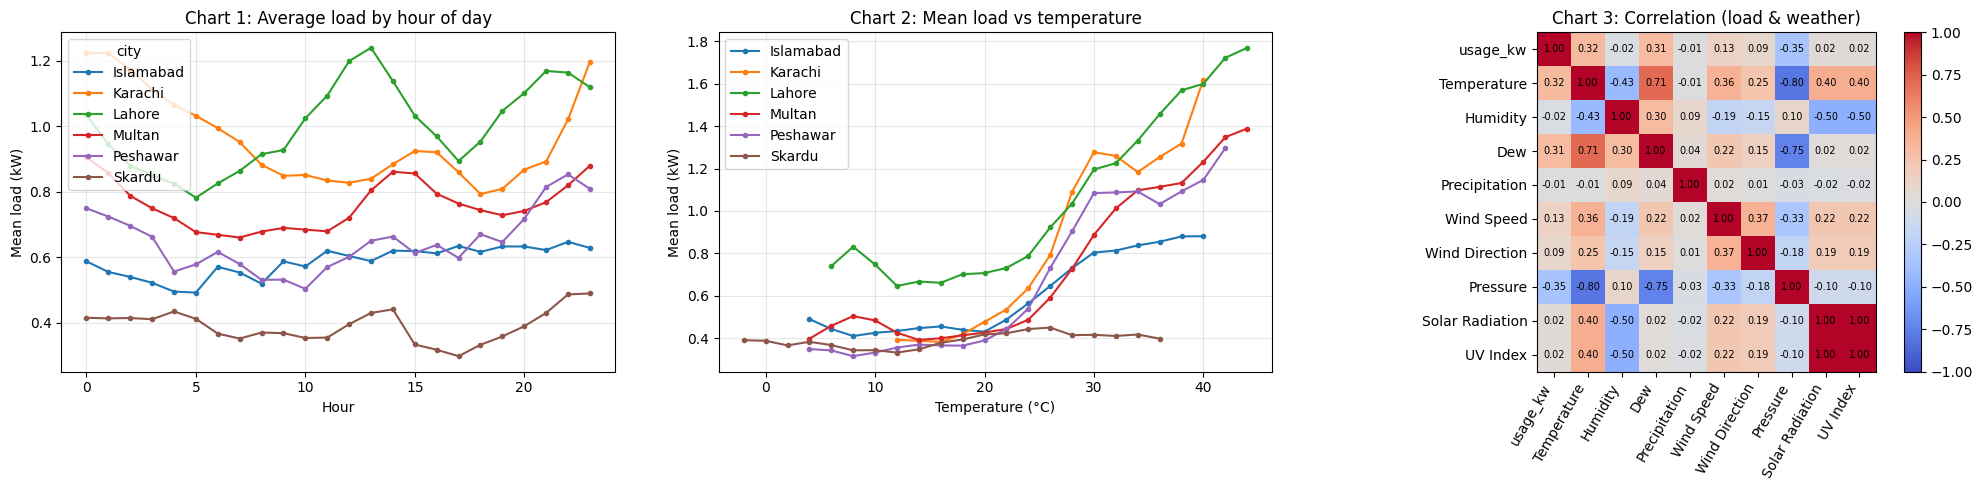


Monthly mean load (kW) by city:
city     Islamabad  Karachi  Lahore  Multan  Peshawar  Skardu
month                                                        
2023-07        NaN      NaN     NaN     NaN       NaN   0.452
2023-08        NaN      NaN     NaN     NaN       NaN   0.470
2023-09      1.603    1.140     NaN   1.179       NaN   0.448
2023-10      1.524    1.157     NaN   0.848     0.532   0.426
2023-11      0.389    0.681   0.675   0.392     0.400   0.454
2023-12      0.388    0.454   0.775   0.430     0.372   0.455
2024-01      0.562    0.410   0.837   0.542     0.391   0.443
2024-02      0.418    0.465   0.678   0.429     0.331   0.289
2024-03      0.411    0.583   0.663   0.396     0.320   0.247
2024-04      0.462    0.867   0.836   0.479     0.347   0.260
2024-05      0.630    1.356   1.431   1.091     0.711   0.330
2024-06      0.827    1.714   1.555   1.378     1.151   0.442
2024-07      0.984    1.530   1.354   1.214     1.444   0.481
2024-08      0.729    1.059   1.126  

In [26]:
# EDA

# Rebuild the correct merged dataframe
df = energy_h.merge(
    weather,
    on=["city", "datetime"],
    how="left"
)

eda = df.dropna(subset=["usage_kw", "Temperature"]).copy()
eda["hour"] = eda.datetime.dt.hour

# --- Timestamp alignment sanity check ---
peak_T = eda.groupby(["city", "hour"]).Temperature.mean().unstack(0).idxmax()
peak_U = eda.groupby(["city", "hour"]).usage_kw.mean().unstack(0).idxmax()
print("Hour of peak temperature:\n", peak_T.to_string())
print("\nHour of peak load:\n", peak_U.to_string())

# --- Summary stats ---
print("\nHourly load (kW) by city:")
print(eda.groupby("city").usage_kw.describe().round(3).to_string())

print("\nMean load per house (kW), spread within each city:")
print(
    eda.groupby(["city", "house_id"])
    .usage_kw.mean()
    .groupby("city")
    .agg(["min", "median", "max"])
    .round(3)
    .to_string()
)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# Chart 1: average daily load profile per city
eda.groupby(["city", "hour"]).usage_kw.mean().unstack(0).plot(
    ax=axes[0], marker="o", ms=3
)
axes[0].set(
    title="Chart 1: Average load by hour of day",
    xlabel="Hour",
    ylabel="Mean load (kW)"
)
axes[0].grid(alpha=.3)

# Chart 2: load vs temperature (2 deg C bins)
eda["t_bin"] = (eda.Temperature / 2).round() * 2
tb = eda.groupby(["city", "t_bin"]).usage_kw.agg(
    ["mean", "count"]
).reset_index()

for city, g in tb[tb["count"] >= 200].groupby("city"):
    axes[1].plot(
        g.t_bin,
        g["mean"],
        marker="o",
        ms=3,
        label=city
    )

axes[1].set(
    title="Chart 2: Mean load vs temperature",
    xlabel="Temperature (°C)",
    ylabel="Mean load (kW)"
)
axes[1].legend()
axes[1].grid(alpha=.3)

# Chart 3: correlation heatmap (pooled)
cols = ["usage_kw"] + weather_cols
corr = eda[cols].corr()

im = axes[2].imshow(
    corr,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

axes[2].set_xticks(range(len(cols)))
axes[2].set_xticklabels(
    cols,
    rotation=60,
    ha="right"
)

axes[2].set_yticks(range(len(cols)))
axes[2].set_yticklabels(cols)

for i in range(len(cols)):
    for j in range(len(cols)):
        axes[2].text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center",
            fontsize=7
        )

axes[2].set_title("Chart 3: Correlation (load & weather)")

plt.colorbar(
    im,
    ax=axes[2],
    fraction=0.046
)

plt.tight_layout()
plt.show()

print("\nMonthly mean load (kW) by city:")
print(
    eda.assign(
        month=eda.datetime.dt.to_period("M")
    )
    .groupby(["month", "city"])
    .usage_kw.mean()
    .unstack()
    .round(3)
    .to_string()
)

#Feature engineering

In [27]:
df = df.sort_values(["house_id", "datetime"]).reset_index(drop=True)
g = df.groupby("house_id")

# --- Lag features (valid because each house has a continuous hourly grid) ---
for L in [1, 2, 3, 6, 24, 48, 168]:
    df[f"lag_{L}"] = g["usage_kw"].shift(L)

# --- Rolling stats on shifted series (never include the current hour) ---
sg = g["usage_kw"].shift(1).groupby(df["house_id"])
df["roll_mean_24"]  = sg.transform(lambda x: x.rolling(24,  min_periods=12).mean())
df["roll_std_24"]   = sg.transform(lambda x: x.rolling(24,  min_periods=12).std())
df["roll_mean_168"] = sg.transform(lambda x: x.rolling(168, min_periods=84).mean())

# --- Time features ---
df["hour"] = df.datetime.dt.hour
df["dayofweek"] = df.datetime.dt.dayofweek
df["is_weekend"] = (df.dayofweek >= 5).astype(int)
df["hour_sin"] = np.sin(2 * np.pi * df.hour / 24);      df["hour_cos"] = np.cos(2 * np.pi * df.hour / 24)
df["dow_sin"]  = np.sin(2 * np.pi * df.dayofweek / 7);  df["dow_cos"]  = np.cos(2 * np.pi * df.dayofweek / 7)

# --- Extra weather features ---
df["temp_lag_1"] = g["Temperature"].shift(1)
df["temp_roll_3"] = g["Temperature"].transform(lambda x: x.rolling(3, min_periods=1).mean())
df["cooling_deg"] = (df.Temperature - 24).clip(lower=0)
df["heating_deg"] = (18 - df.Temperature).clip(lower=0)

# --- City one-hot ---
city_dummies = pd.get_dummies(df["city"], prefix="city", dtype=int)
df = pd.concat([df, city_dummies], axis=1)

LAG_FEATS   = [f"lag_{L}" for L in [1, 2, 3, 6, 24, 48, 168]] + ["roll_mean_24", "roll_std_24", "roll_mean_168"]
TIME_FEATS  = ["hour", "dayofweek", "is_weekend", "hour_sin", "hour_cos", "dow_sin", "dow_cos"]
WEATHER_FEATS = weather_cols + ["temp_lag_1", "temp_roll_3", "cooling_deg", "heating_deg"]
CITY_FEATS  = list(city_dummies.columns)
FEATURES = LAG_FEATS + TIME_FEATS + WEATHER_FEATS + CITY_FEATS
TARGET = "usage_kw"

model_df = df.dropna(subset=FEATURES + [TARGET]).reset_index(drop=True)
print(f"Rows usable for modelling: {len(model_df):,} (from {len(df):,})")
print(f"Number of features: {len(FEATURES)}")

Rows usable for modelling: 552,005 (from 599,715)
Number of features: 36


#train/validation/test split

In [28]:
t_min, t_max = model_df.datetime.min(), model_df.datetime.max()
span = t_max - t_min
train_end = (t_min + 0.70 * span).normalize()
val_end   = (t_min + 0.85 * span).normalize()

train = model_df[model_df.datetime <  train_end]
val   = model_df[(model_df.datetime >= train_end) & (model_df.datetime < val_end)]
test  = model_df[model_df.datetime >= val_end]

X_train, y_train = train[FEATURES], train[TARGET]
X_val,   y_val   = val[FEATURES],   val[TARGET]
X_test,  y_test  = test[FEATURES],  test[TARGET]

for name, d in [("Train", train), ("Validation", val), ("Test", test)]:
    print(f"{name:10s} {d.datetime.min().date()} -> {d.datetime.max().date()} | rows: {len(d):>8,}")

print("\nRows per city in each split (all cities should appear in train):")
print(pd.DataFrame({"train": train.city.value_counts(), "val": val.city.value_counts(),
                    "test": test.city.value_counts()}).fillna(0).astype(int).to_string())

Train      2023-07-26 -> 2024-07-03 | rows:  388,932
Validation 2024-07-04 -> 2024-09-15 | rows:  102,588
Test       2024-09-16 -> 2024-11-28 | rows:   60,485

Rows per city in each split (all cities should appear in train):
            train    val   test
city                           
Islamabad   53457  16094   8017
Karachi     58478  16924   9510
Lahore      45963  15607   9924
Multan      56182  16443  10124
Peshawar   113817  31968  19440
Skardu      61035   5552   3470


#Random Forest

In [29]:
import time
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=16,
    min_samples_leaf=10,
    max_features=0.5,
    max_samples=0.3,
    n_jobs=-1,
    random_state=42
)

# Train
t0 = time.time()
rf_model.fit(X_train, y_train)

# Predict
rf_pred = rf_model.predict(X_val)

# Evaluation
mae = mean_absolute_error(y_val, rf_pred)
rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
r2 = r2_score(y_val, rf_pred)

fit_time = time.time() - t0

print("Random Forest Results")
print("---------------------")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))
print("Training time:", round(fit_time, 1), "seconds")

Random Forest Results
---------------------
MAE : 0.2842
RMSE: 0.475
R²  : 0.7758
Training time: 41.9 seconds


#XGBoost Regressor

In [31]:
%pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.5/48.9 MB 1.6 MB/s eta 0:00:30
   - -------------------------------------- 1.8/48.9 MB 3.8 MB/s eta 0:00:13
   --- ------------------------------------ 3.9/48.9 MB 6.1 MB/s eta 0:00:08
   ------- -------------------------------- 8.9/48.9 MB 10.2 MB/s eta 0:00:04
   --------- ------------------------------ 12.1/48.9 MB 12.4 MB/s eta 0:00:03
   --------- ------------------------------ 12.1/48.9 MB 12.4 MB/s eta 0:00:03
   --------- ------------------------------ 12.1/48.9 MB 12.4 MB/s eta 0:00:03
   ---------- ----------------------------- 12.3/48.9 MB 7.8 MB/s eta 0:00:05
   ---------- ----


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import time
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create XGBoost model
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.08,
    max_depth=8,
    min_child_weight=10,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    objective="reg:squarederror",
    n_jobs=-1,
    random_state=42
)

# Train
t0 = time.time()
xgb_model.fit(X_train, y_train)

# Predict
xgb_pred = xgb_model.predict(X_val)

# Evaluation
mae = mean_absolute_error(y_val, xgb_pred)
rmse = np.sqrt(mean_squared_error(y_val, xgb_pred))
r2 = r2_score(y_val, xgb_pred)

fit_time = time.time() - t0

print("XGBoost Results")
print("----------------")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))
print("Training time:", round(fit_time, 1), "seconds")

XGBoost Results
----------------
MAE : 0.2824
RMSE: 0.4693
R²  : 0.7812
Training time: 7.8 seconds


# Final Test Evaluation - XGBoost

In [33]:
xgb_test_pred = xgb_model.predict(X_test)

test_mae = mean_absolute_error(y_test, xgb_test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, xgb_test_pred))
test_r2 = r2_score(y_test, xgb_test_pred)

print("XGBoost - FINAL TEST RESULTS")
print("----------------------------")
print("MAE :", round(test_mae, 4))
print("RMSE:", round(test_rmse, 4))
print("R²  :", round(test_r2, 4))

XGBoost - FINAL TEST RESULTS
----------------------------
MAE : 0.2191
RMSE: 0.3996
R²  : 0.7611


#LightGBM Regressor

In [35]:
%pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.9 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 3.2 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import time
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

lgbm_model = LGBMRegressor(
    n_estimators=300,
    learning_rate=0.08,
    max_depth=8,
    num_leaves=63,
    min_child_samples=50,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=-1,
    random_state=42
)

t0 = time.time()
lgbm_model.fit(X_train, y_train)

lgbm_pred = lgbm_model.predict(X_test)

mae = mean_absolute_error(y_test, lgbm_pred)
rmse = np.sqrt(mean_squared_error(y_test, lgbm_pred))
r2 = r2_score(y_test, lgbm_pred)

print("LightGBM - FINAL TEST RESULTS")
print("-----------------------------")
print("MAE :", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R²  :", round(r2, 4))
print("Training time:", round(time.time() - t0, 1), "seconds")

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.035601 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 5545
[LightGBM] [Info] Number of data points in the train set: 388932, number of used features: 36
[LightGBM] [Info] Start training from score 0.625969
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive

In [37]:
import joblib

joblib.dump(lgbm_model, "lightgbm_energy_model.pkl")

print("Model saved successfully!")

Model saved successfully!
